In [1]:
import oracledb
import pandas as pd
import numpy as np
import os
import dateutil
from datetime import datetime
from dateutil.parser import parse
from datetime import date
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import duckdb
import gc
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [41]:
#import monthly CPI data
cpi_df = pd.read_csv('CPI.csv')
cpi_df.head()

,observation_date,CORESTICKM159SFRBATL
0,1968-01-01,3.651861
1,1968-02-01,3.673819
2,1968-03-01,4.142164
3,1968-04-01,4.155828
4,1968-05-01,4.088245


In [42]:
#check for null values
cpi_df.isnull().sum()

observation_date        0
CORESTICKM159SFRBATL    0
dtype: int64

In [43]:
#pull out year and month
#also note year month is reporting, need to use prior observation for actual CPI for month
cpi_df['YEAR'] = cpi_df['observation_date'].str[0:4].astype('int')
cpi_df['MONTH'] = cpi_df['observation_date'].str[5:7].astype('int')
cpi_df['CPI'] = cpi_df['CORESTICKM159SFRBATL'].shift()
cpi_df.head()

,observation_date,CORESTICKM159SFRBATL,YEAR,MONTH,CPI
0,1968-01-01,3.651861,1968,1,NaN
1,1968-02-01,3.673819,1968,2,3.651861
2,1968-03-01,4.142164,1968,3,3.673819
3,1968-04-01,4.155828,1968,4,4.142164
4,1968-05-01,4.088245,1968,5,4.155828


In [44]:
#create year month for my index and clean up data
cpi_df.dropna(subset=['CPI'], inplace=True)

cpi_df['YEAR_MONTH'] = cpi_df['YEAR']*100 + cpi_df['MONTH']

cpi_df = cpi_df.drop(columns = ['observation_date','YEAR','MONTH','CORESTICKM159SFRBATL'])
cpi_df.set_index('YEAR_MONTH', inplace=True)
cpi_df.head()

,CPI
YEAR_MONTH,
196802,3.651861
196803,3.673819
196804,4.142164
196805,4.155828
196806,4.088245


In [45]:
#import monthly gas prices
gas_df = pd.read_csv('Monthly Gas Prices.csv')
gas_df.head()

,Date,PRICE
0,4/15/1993,1.078
1,5/15/1993,1.100
2,6/15/1993,1.097
3,7/15/1993,1.078
4,8/15/1993,1.062


In [46]:
#check for null values
gas_df.isnull().sum()

Date     1
PRICE    1
dtype: int64

In [47]:
print(gas_df[gas_df.isna().any(axis=1)])

    Date  PRICE
403  NaN    NaN


In [48]:
#i just have a garbage row
gas_df.dropna(inplace=True)

In [49]:
#create year month index and clean up data
gas_df['date_col'] = pd.to_datetime(gas_df['Date'])

gas_df['YEAR'] = gas_df['date_col'].dt.year
gas_df['MONTH'] = gas_df['date_col'].dt.month

gas_df['YEAR_MONTH'] = gas_df['YEAR']*100 + gas_df['MONTH']

gas_df.dropna(subset=['YEAR_MONTH'], inplace=True)

gas_df['YEAR_MONTH'] = gas_df['YEAR_MONTH'].astype('int')


gas_df = gas_df.rename(columns = {'PRICE':'PRICE_OF_GAS'})

gas_df = gas_df.drop(columns = ['Date','date_col','YEAR','MONTH'])
gas_df.set_index('YEAR_MONTH', inplace=True)
gas_df.head()

,PRICE_OF_GAS
YEAR_MONTH,
199304,1.078
199305,1.100
199306,1.097
199307,1.078
199308,1.062


In [50]:
#import monthly unemployment rate
ue_rate_df = pd.read_csv('Unemployment rate.csv')
ue_rate_df.head()

,observation_date,UNRATE
0,1948-01-01,3.4
1,1948-02-01,3.8
2,1948-03-01,4.0
3,1948-04-01,3.9
4,1948-05-01,3.5


In [51]:
#check for null values
ue_rate_df.isnull().sum()

observation_date    0
UNRATE              1
dtype: int64

In [52]:
print(ue_rate_df[ue_rate_df['UNRATE'].isnull()])

    observation_date  UNRATE
933       2025-10-01     NaN


In [53]:
#missing Oct 2025 due to government shutdown, use average UE rate from prior and after month
ue_rate_df['UNRATE'].infer_objects(copy=False).interpolate(inplace=True)

In [54]:
#inpsect interpolation
print(ue_rate_df[ue_rate_df['observation_date'].isin(['2025-10-01', '2025-09-01', '2025-11-01'])])

    observation_date  UNRATE
932       2025-09-01    4.40
933       2025-10-01    4.45
934       2025-11-01    4.50


In [55]:
#unemployment rate is from month prior
ue_rate_df['UE_RATE'] = ue_rate_df['UNRATE'].shift()
ue_rate_df.head()

,observation_date,UNRATE,UE_RATE
0,1948-01-01,3.4,NaN
1,1948-02-01,3.8,3.4
2,1948-03-01,4.0,3.8
3,1948-04-01,3.9,4.0
4,1948-05-01,3.5,3.9


In [58]:
#create the year month index and clean up data
ue_rate_df.dropna(subset=['UE_RATE'], inplace=True)

ue_rate_df['YEAR'] = ue_rate_df['observation_date'].str[0:4].astype('int')
ue_rate_df['MONTH'] = ue_rate_df['observation_date'].str[5:7].astype('int')

ue_rate_df['YEAR_MONTH'] = ue_rate_df['YEAR']*100 + ue_rate_df['MONTH']

ue_rate_df = ue_rate_df.drop(columns = ['observation_date','YEAR','MONTH','UNRATE'])
ue_rate_df.set_index('YEAR_MONTH', inplace=True)
ue_rate_df.head()

,UE_RATE
YEAR_MONTH,
194802,3.4
194803,3.8
194804,4.0
194805,3.9
194806,3.5


In [59]:
#combine data sets and produce correlation matrix
monthly_df = pd.concat([cpi_df,gas_df,ue_rate_df], axis=1, join='inner')
monthly_df.dtypes

corr_matrix = monthly_df[['CPI','PRICE_OF_GAS','UE_RATE']].corr()
print(corr_matrix)

                   CPI  PRICE_OF_GAS   UE_RATE
CPI           1.000000      0.080849 -0.541140
PRICE_OF_GAS  0.080849      1.000000  0.050007
UE_RATE      -0.541140      0.050007  1.000000


In [60]:
#for gas need the month over month increase
monthly_df['GAS_PRIOR_MONTH'] = monthly_df['PRICE_OF_GAS'].shift()
monthly_df['GAS_PRIOR_YEAR'] = monthly_df['PRICE_OF_GAS'].shift(12)

monthly_df.dropna(subset=['GAS_PRIOR_YEAR'], inplace=True)

monthly_df['GAS_MOM_PCNT'] = (monthly_df['PRICE_OF_GAS'] - monthly_df['GAS_PRIOR_MONTH'])/monthly_df['GAS_PRIOR_MONTH']
monthly_df['GAS_YOY_PCNT'] = (monthly_df['PRICE_OF_GAS'] - monthly_df['GAS_PRIOR_YEAR'])/monthly_df['GAS_PRIOR_YEAR']
monthly_df.head()

,CPI,PRICE_OF_GAS,UE_RATE,GAS_PRIOR_MONTH,GAS_PRIOR_YEAR,GAS_MOM_PCNT,GAS_YOY_PCNT
YEAR_MONTH,,,,,,,
199404,3.570151,1.027,6.5,1.008,1.078,0.018849,-0.047310
199405,3.354398,1.047,6.4,1.027,1.100,0.019474,-0.048182
199406,3.225533,1.078,6.1,1.047,1.097,0.029608,-0.017320
199407,3.194738,1.106,6.1,1.078,1.078,0.025974,0.025974
199408,3.233880,1.155,6.1,1.106,1.062,0.044304,0.087571


In [61]:
corr_matrix = monthly_df[['CPI','PRICE_OF_GAS','UE_RATE','GAS_MOM_PCNT','GAS_YOY_PCNT']].corr()
print(corr_matrix)

                   CPI  PRICE_OF_GAS   UE_RATE  GAS_MOM_PCNT  GAS_YOY_PCNT
CPI           1.000000      0.118508 -0.567023     -0.082980     -0.094850
PRICE_OF_GAS  0.118508      1.000000  0.084540      0.075587      0.219431
UE_RATE      -0.567023      0.084540  1.000000      0.064964     -0.081574
GAS_MOM_PCNT -0.082980      0.075587  0.064964      1.000000      0.266067
GAS_YOY_PCNT -0.094850      0.219431 -0.081574      0.266067      1.000000


In [62]:
del cpi_df
del gas_df
del ue_rate_df
gc.collect()

794

In [63]:
#import certegy monthly file, check for null values
certegy_df = pd.read_csv('Certegy Monthly.csv')
certegy_df.isnull().sum()

MONTH                            0
ATTEMPT_DOLLARS_115546           0
AVG_ATTEMPT_AMT_115546           0
APPROVE_DOLLARS_115546           0
NET_LOSS_DLRS_115546             0
NLR_115546                       0
ATTEMPT_DOLLARS_289842           0
AVG_ATTEMPT_AMT_289842           0
APPROVE_DOLLARS_289842           0
NET_LOSS_DLRS_289842             0
NLR_289842                       0
ATTEMPT_DOLLARS_470000           0
AVG_ATTEMPT_AMT_470000           0
APPROVE_DOLLARS_470000           0
NET_LOSS_DLRS_470000             0
NLR_470000                       1
ATTEMPT_DOLLARS_888800           0
AVG_ATTEMPT_AMT_888800           0
APPROVE_DOLLARS_888800           0
NET_LOSS_DLRS_888800             0
NLR_888800                       0
ATTEMPT_DOLLARS_189925           0
AVG_ATTEMPT_AMT_189925           0
APPROVE_DOLLARS_189925           0
NET_LOSS_DLRS_189925             0
NLR_189925                       0
ATTEMPT_DOLLARS_9910             0
AVG_ATTEMPT_AMT_9910             0
APPROVE_DOLLARS_9910

In [64]:
#interpolate missing
certegy_df['NLR_470000'].infer_objects(copy=False).interpolate(inplace=True)
certegy_df.isnull().sum()

MONTH                            0
ATTEMPT_DOLLARS_115546           0
AVG_ATTEMPT_AMT_115546           0
APPROVE_DOLLARS_115546           0
NET_LOSS_DLRS_115546             0
NLR_115546                       0
ATTEMPT_DOLLARS_289842           0
AVG_ATTEMPT_AMT_289842           0
APPROVE_DOLLARS_289842           0
NET_LOSS_DLRS_289842             0
NLR_289842                       0
ATTEMPT_DOLLARS_470000           0
AVG_ATTEMPT_AMT_470000           0
APPROVE_DOLLARS_470000           0
NET_LOSS_DLRS_470000             0
NLR_470000                       0
ATTEMPT_DOLLARS_888800           0
AVG_ATTEMPT_AMT_888800           0
APPROVE_DOLLARS_888800           0
NET_LOSS_DLRS_888800             0
NLR_888800                       0
ATTEMPT_DOLLARS_189925           0
AVG_ATTEMPT_AMT_189925           0
APPROVE_DOLLARS_189925           0
NET_LOSS_DLRS_189925             0
NLR_189925                       0
ATTEMPT_DOLLARS_9910             0
AVG_ATTEMPT_AMT_9910             0
APPROVE_DOLLARS_9910

In [65]:
#set index as year month
certegy_df.set_index('YEAR_MONTH', inplace=True)

In [66]:
#create binary dummy variables for month
certegy_df = pd.get_dummies(certegy_df, columns=['MONTH'], drop_first=True, dtype=int)
certegy_df.dtypes

ATTEMPT_DOLLARS_115546           float64
AVG_ATTEMPT_AMT_115546           float64
APPROVE_DOLLARS_115546           float64
NET_LOSS_DLRS_115546             float64
NLR_115546                       float64
ATTEMPT_DOLLARS_289842           float64
AVG_ATTEMPT_AMT_289842           float64
APPROVE_DOLLARS_289842           float64
NET_LOSS_DLRS_289842             float64
NLR_289842                       float64
ATTEMPT_DOLLARS_470000           float64
AVG_ATTEMPT_AMT_470000           float64
APPROVE_DOLLARS_470000           float64
NET_LOSS_DLRS_470000             float64
NLR_470000                       float64
ATTEMPT_DOLLARS_888800           float64
AVG_ATTEMPT_AMT_888800           float64
APPROVE_DOLLARS_888800           float64
NET_LOSS_DLRS_888800             float64
NLR_888800                       float64
ATTEMPT_DOLLARS_189925           float64
AVG_ATTEMPT_AMT_189925           float64
APPROVE_DOLLARS_189925           float64
NET_LOSS_DLRS_189925             float64
NLR_189925      

In [67]:
#combine with economic data
monthly_cert_df = pd.concat([monthly_df,certegy_df], axis=1, join='inner')
monthly_cert_df.dtypes

CPI                float64
PRICE_OF_GAS       float64
UE_RATE            float64
GAS_PRIOR_MONTH    float64
GAS_PRIOR_YEAR     float64
                    ...   
MONTH_8              int64
MONTH_9              int64
MONTH_10             int64
MONTH_11             int64
MONTH_12             int64
Length: 65, dtype: object

In [68]:
#now create all of my lag variables
#start with a list of features, I need to filter out what I don't calculate a lag for
var_list = monthly_cert_df.columns.tolist()

var_list = [item for item in var_list if not item.startswith("MONTH")]
var_list.remove("PRICE_OF_GAS")
var_list.remove("GAS_PRIOR_MONTH")
var_list.remove("GAS_PRIOR_YEAR")

In [69]:
#FUNCTION TO LOOP THROUGH MY AND CREATE LAG VARIABLES
def create_lags(df: pd.DataFrame, columns: list, lags: list) -> pd.DataFrame:
    result_df = df.copy()
    lagged_cols = {}
    
    for col in columns:
        for lag in lags:
            new_col_name = f"{col}_lag_{lag}"
            lagged_cols[new_col_name] = df[col].shift(lag)
    
    lagged_df = pd.DataFrame(lagged_cols, index=df.index)
    
    return pd.concat([result_df, lagged_df], axis=1)
#I want 1 - 6 and 12 month lags
monthly_cert_df_lags = create_lags(monthly_cert_df, columns=var_list, lags=[1, 2, 3, 4, 5, 6, 12])
#drop observations that will be outside the study range
monthly_cert_df_lags.dropna(subset=['GAS_YOY_PCNT_lag_12'], inplace=True)

In [70]:
#mark pandemic dates and create a post pandemic data frame
monthly_cert_df_lags['PANDEMIC'] = ((monthly_cert_df_lags.index >= 202002) & (monthly_cert_df_lags.index <= 202201)).astype(int)
df_post_pandemic = monthly_cert_df_lags[monthly_cert_df_lags.index >= 202201]

In [97]:
#create variable list for running individual regressions
var_list_w_lags = monthly_cert_df_lags.columns.tolist()

var_list_w_lags = [item for item in var_list_w_lags if not item.startswith("MONTH")]
var_list_w_lags.remove("PRICE_OF_GAS")
var_list_w_lags.remove("PANDEMIC")

In [108]:
#pick a variable to understand (dependent variable) and run individual regressions for each independent variable
def run_individual_regressions(df, feature_list, target_col):
  results = []
  y = df[[target_col]]
    
  for col in feature_list:
    if col == target_col:
        continue
    X = df[[col]]
    model = LinearRegression()
    model.fit(X, y)

    coef = model.coef_[0][0]
    intercept = model.intercept_[0]
    r2 = model.score(X, y)

    results.append({
        'feature': col,
        'coefficient': coef,
        'intercept': intercept,
        'r2_score': r2,
    })
      
  return pd.DataFrame(results)

res_df = run_individual_regressions(monthly_cert_df_lags, feature_list=var_list_w_lags, target_col='NLR_9800')
res_df.sort_values(by='r2_score', ascending=False, inplace=True)
res_df.head(20)

,feature,coefficient,intercept,r2_score
39,NET_LOSS_DLRS_9800,5.628980e-08,0.000080,0.680919
42,NLR_269025_Y,1.584930e+00,-0.001072,0.271874
262,AVG_ATTEMPT_AMT_9910_lag_1,1.099803e-06,-0.001595,0.243266
32,AVG_ATTEMPT_AMT_9910,1.021196e-06,-0.001376,0.212810
344,NLR_269025_Y_lag_6,1.388082e+00,-0.000655,0.203760
148,NLR_289842_lag_6,2.940259e-01,0.000554,0.180621
169,APPROVE_DOLLARS_470000_lag_6,-3.149090e-10,0.002482,0.180531
327,ATTEMPT_DLRS_269025_Y_lag_3,-1.401183e-12,0.002971,0.178103
339,NLR_269025_Y_lag_1,1.289145e+00,-0.000544,0.177809
168,APPROVE_DOLLARS_470000_lag_5,-3.142264e-10,0.002467,0.177269


<Axes: xlabel='YEAR_MONTH'>

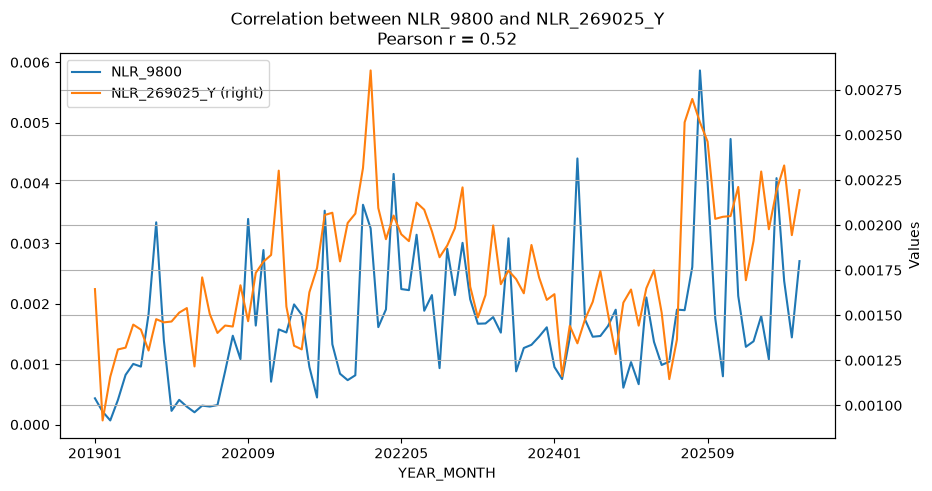

In [109]:
#monthly plot to see correlation
def plot_corr(df, col1, col2):
    # Calculate the correlation coefficient
    correlation_value = df[col1].corr(df[col2])

    #need to convert the index to a string for the plot
    plot_df = df[[col1, col2]].copy()
    plot_df.index = plot_df.index.astype(str)

    # Plot both columns using the index for the x-axis
    ax = plot_df[col1].plot(figsize=(10, 5), label=col1, legend=True)
    plot_df[col2].plot(secondary_y=True, ax=ax, label=col2, legend=True)

    # Customize the chart appearance
    plt.title(f"Correlation between {col1} and {col2}\nPearson r = {correlation_value:.2f}")
    plt.xlabel(df.index.name if df.index.name else "Index")
    plt.ylabel("Values")
    plt.grid(True)

    return ax

plot_corr(monthly_cert_df_lags, col1 = "NLR_9800", col2 = "NLR_269025_Y")
#plot_corr(df_post_pandemic, col1 = "NLR_9800", col2 = "NLR_269025_Y")

In [110]:
#let's run actual regression models 
y = monthly_cert_df_lags[['NLR_9800']]
X = monthly_cert_df_lags[['CPI','GAS_MOM_PCNT','GAS_YOY_PCNT','MONTH_2','MONTH_3','MONTH_4','MONTH_5','MONTH_6','MONTH_7',
                          'MONTH_8','MONTH_9','MONTH_10','MONTH_11','MONTH_12','UE_RATE','PANDEMIC','NLR_269025_Y']]

#better to do this with statsmodels
X_constant = sm.add_constant(X) 
sm_model = sm.OLS(y, X_constant).fit()

print(sm_model.summary())

                            OLS Regression Results                            
Dep. Variable:               NLR_9800   R-squared:                       0.405
Model:                            OLS   Adj. R-squared:                  0.271
Method:                 Least Squares   F-statistic:                     3.008
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           0.000541
Time:                        13:15:11   Log-Likelihood:                 523.53
No. Observations:                  93   AIC:                            -1011.
Df Residuals:                      75   BIC:                            -965.5
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0021      0.001     -2.398   

September and April show a positive influence but the investigation into NLR_269025_Y is what is going to be going forward